# SVD Image Compression — a from-scratch tour (MAT248)

**Idea.** A grayscale image is just an $m\times n$ matrix of numbers. The **Singular Value Decomposition** writes any matrix as a sum of simple rank-one "layers", ordered from most to least important. Keeping only the first $k$ layers gives a *compressed* image that is, in a precise sense, the best possible rank-$k$ approximation.

In this notebook we
1. treat an image as a matrix,
2. state the SVD and what each factor means,
3. **compute the SVD ourselves** (Jacobi eigenvalue method on $A^TA$; no `np.linalg.svd`),
4. check it on a $2\times2$ example and against NumPy (one clearly labelled cell),
5. build low-rank approximations, measure error (Eckart–Young) and storage, and
6. extend to colour images.

Only `numpy` and `matplotlib` are required (`ipywidgets` is optional, for one slider).

## 0. Setup
We import the libraries and locate the sample images that ship with this repository.

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "image.cmap": "gray", "axes.grid": False})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

# Works whether Jupyter was started in notebook/ or in the repo root.
SAMPLES = next(p for p in ("../svdcomp/demo_assets/samples", "svdcomp/demo_assets/samples") if os.path.isdir(p))

def show(ax, img, title="", **kw):
    ax.imshow(img, vmin=kw.pop("vmin", 0), vmax=kw.pop("vmax", 1), **kw)
    ax.set_title(title, fontsize=10); ax.axis("off")

## 1. Images are matrices
A grayscale image with $m$ rows and $n$ columns is a matrix $A\in\mathbb R^{m\times n}$; entry $A_{ij}$ is the brightness of pixel $(i,j)$ (here scaled to $[0,1]$, with $0$ = black and $1$ = white). Compression therefore becomes a question about *matrices*: can we describe $A$ with far fewer than $mn$ numbers?

shape = (256, 256)  ->  256 x 256 = 65536 numbers,  range [0.00, 1.00]

A 6x6 block of pixel values scaled to 0..255:
 [[ 9 10 11 11 11 10]
 [11  8 11 11 10  9]
 [ 9 11 11 11 10 11]
 [ 9  8 10 11  9 10]
 [ 8  9 10  9 11  9]
 [ 9  8  7  9 13 10]]


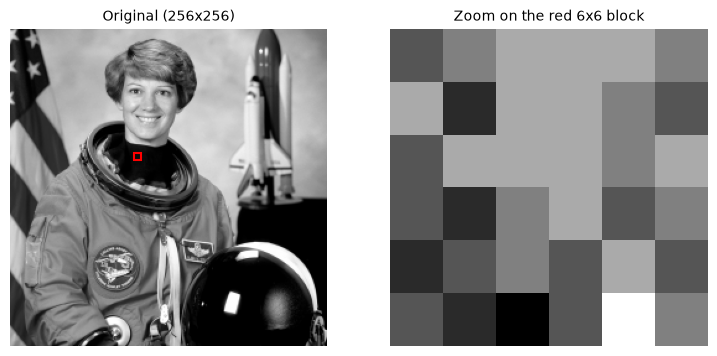

In [2]:
A = plt.imread(f"{SAMPLES}/photo-gray.png").astype(float)
if A.ndim == 3: A = A[:, :, 0]          # keep one channel if the PNG is stored as RGB
m, n = A.shape
print(f"shape = {A.shape}  ->  {m} x {n} = {m*n} numbers,  range [{A.min():.2f}, {A.max():.2f}]")

r0, c0 = 100, 100                        # top-left corner of a 6x6 zoom block
block = A[r0:r0+6, c0:c0+6]
print("\nA 6x6 block of pixel values scaled to 0..255:\n", np.round(255 * block).astype(int))

fig, ax = plt.subplots(1, 2, figsize=(9, 4.3))
show(ax[0], A, f"Original ({m}x{n})")
ax[0].add_patch(plt.Rectangle((c0-.5, r0-.5), 6, 6, fill=False, ec="red", lw=1.5))
show(ax[1], block, "Zoom on the red 6x6 block", interpolation="nearest", vmin=block.min(), vmax=block.max())
plt.show()

## 2. The Singular Value Decomposition
**Theorem (SVD).** Every real $m\times n$ matrix $A$ can be written
$$A = U\,\Sigma\,V^{T},$$
where

* $U\in\mathbb R^{m\times m}$ is **orthogonal** ($U^TU=I$): its columns $u_1,\dots,u_m$ (*left singular vectors*) are an orthonormal basis of the output space;
* $V\in\mathbb R^{n\times n}$ is **orthogonal** ($V^TV=I$): its columns $v_1,\dots,v_n$ (*right singular vectors*) are an orthonormal basis of the input space;
* $\Sigma$ is "diagonal" with **singular values** $\sigma_1\ge\sigma_2\ge\dots\ge\sigma_r>0$ (and zeros), $r=\operatorname{rank}A$.

Geometrically, $A$ rotates/reflects ($V^T$), stretches along the coordinate axes by $\sigma_i$ ($\Sigma$), then rotates/reflects again ($U$). Equivalently $Av_i=\sigma_i u_i$.

Multiplying out $U\Sigma V^T$ column by column gives the **sum of rank-one matrices**
$$A=\sum_{i=1}^{r}\sigma_i\,u_i v_i^{T}.$$
Each term $u_iv_i^T$ is an *outer product*: an $m\times n$ matrix of rank 1 that costs only $m+n$ numbers to store. The weight $\sigma_i$ says how much that layer contributes. Because the $\sigma_i$ decay quickly for natural images, the first few layers already capture most of the picture.

## 3. Why the SVD exists, and how to compute it
Start from the matrix $A^TA\in\mathbb R^{n\times n}$.

* It is **symmetric**: $(A^TA)^T=A^TA$.
* It is **positive semidefinite**: $x^TA^TAx=\|Ax\|^2\ge0$, so all eigenvalues are $\lambda_i\ge0$.

By the **spectral theorem**, a symmetric matrix has an orthonormal eigenbasis: $A^TA=V\Lambda V^T$ with $V$ orthogonal and $\Lambda=\operatorname{diag}(\lambda_1\ge\dots\ge\lambda_n\ge0)$. Define
$$\sigma_i=\sqrt{\lambda_i},\qquad u_i=\frac{Av_i}{\sigma_i}\quad(\sigma_i>0).$$
Then the $u_i$ are orthonormal: $u_i^Tu_j=\dfrac{v_i^TA^TAv_j}{\sigma_i\sigma_j}=\dfrac{\lambda_j\,v_i^Tv_j}{\sigma_i\sigma_j}=\delta_{ij}$, and $Av_i=\sigma_iu_i$ — which is exactly $A=U\Sigma V^T$.

**Recipe:** (1) form $A^TA$; (2) find its eigenpairs; (3) $\sigma_i=\sqrt{\lambda_i}$; (4) $u_i=Av_i/\sigma_i$.

**Step 2 from scratch: the Jacobi eigenvalue method.** For a symmetric $S$, pick an off-diagonal entry $S_{pq}\ne0$ and apply a plane rotation $J$ (angle $\theta$ in the $(p,q)$ plane) chosen so that $(J^TSJ)_{pq}=0$. That requires $\tan 2\theta = 2S_{pq}/(S_{pp}-S_{qq})$; with $t=\tan\theta$ the stable root is
$$t=\frac{\operatorname{sign}(\vartheta)}{|\vartheta|+\sqrt{\vartheta^2+1}},\quad \vartheta=\frac{S_{qq}-S_{pp}}{2S_{pq}},\quad c=\frac1{\sqrt{t^2+1}},\; s=tc.$$
Each rotation preserves the sum of squares of all entries while moving weight onto the diagonal. Sweeping over all pairs $(p,q)$ repeatedly drives the matrix to a diagonal $\Lambda$, and the accumulated product of rotations is $V$. It is simple, always converges, and takes a few seconds for a $256\times256$ image, so **no downscaling is needed**.

*Caveat.* Forming $A^TA$ squares the condition number: the eigenvalues $\lambda_i=\sigma_i^2$ carry an absolute error of about $\varepsilon\lambda_1$, so for tiny $\sigma_i$ the vectors $u_i=Av_i/\sigma_i$ lose orthogonality. We therefore treat singular values below $10^{-3}\sigma_1$ as zero (they are visually irrelevant for this image); production libraries use more careful algorithms.

In [3]:
def jacobi_eig(S, tol=1e-13, max_sweeps=30):
    '''Eigen-decomposition of a symmetric matrix S by cyclic Jacobi rotations. Returns (eigenvalues, V).'''
    S = S.copy(); N = S.shape[0]; V = np.eye(N)
    for sweep in range(max_sweeps):
        total = np.sqrt(np.sum(S**2))
        if np.sqrt(np.sum(S**2) - np.sum(np.diag(S)**2)) <= tol * total:   # off-diagonal part ~ 0
            break
        for p in range(N - 1):
            for q in range(p + 1, N):
                if abs(S[p, q]) < 1e-15 * total: continue                 # already negligible
                th = (S[q, q] - S[p, p]) / (2 * S[p, q])
                t = (1.0 if th >= 0 else -1.0) / (abs(th) + np.sqrt(th * th + 1))
                c = 1 / np.sqrt(t * t + 1); s = t * c
                for M in (S, V):                                           # M <- M J  (mix columns p, q)
                    Mp = M[:, p].copy(); M[:, p] = c * Mp - s * M[:, q]; M[:, q] = s * Mp + c * M[:, q]
                Sp = S[p, :].copy(); S[p, :] = c * Sp - s * S[q, :]; S[q, :] = s * Sp + c * S[q, :]   # S <- J^T S
    return np.diag(S).copy(), V

def my_svd(A, rel_tol=1e-3):
    '''Thin SVD A = U diag(s) V^T via the eigen-decomposition of A^T A. Drops sigma_i <= rel_tol * sigma_1 (numerically unreliable).'''
    A = np.asarray(A, dtype=float)
    if A.shape[0] < A.shape[1]:                       # work with the smaller Gram matrix
        V, s, U = my_svd(A.T, rel_tol); return U, s, V
    lam, V = jacobi_eig(A.T @ A)                      # steps 1-2: eigenpairs of A^T A
    order = np.argsort(lam)[::-1]; lam, V = lam[order], V[:, order]
    s = np.sqrt(np.clip(lam, 0, None))                # step 3: sigma = sqrt(lambda)
    r = int(np.sum(s > rel_tol * s[0]))               # numerical rank
    s, V = s[:r], V[:, :r]
    U = (A @ V) / s                                   # step 4: u_i = A v_i / sigma_i
    return U, s, V

t0 = time.time()
U, s, V = my_svd(A)
print(f"SVD of the {m}x{n} image in {time.time()-t0:.1f} s; numerical rank r = {len(s)}")
print("largest singular values:", s[:5])

SVD of the 256x256 image in 2.9 s; numerical rank r = 188
largest singular values: [122.7683  36.6194  22.738   19.0863  15.7806]


## 4. A hand-checkable $2\times2$ example
Take $A=\begin{pmatrix}3&0\\4&5\end{pmatrix}$. Then $A^TA=\begin{pmatrix}25&20\\20&25\end{pmatrix}$ has characteristic polynomial $(25-\lambda)^2-400=0$, so $\lambda=45,\,5$ and
$$\sigma_1=\sqrt{45}=3\sqrt5\approx6.708,\qquad \sigma_2=\sqrt5\approx2.236,$$
with eigenvectors $v_1=\tfrac1{\sqrt2}(1,1)^T$, $v_2=\tfrac1{\sqrt2}(1,-1)^T$ and $u_i=Av_i/\sigma_i$. Check: $\sigma_1\sigma_2=15=|\det A|$. Let us see that our function agrees (signs of paired $u_i,v_i$ may flip together).

In [4]:
B = np.array([[3., 0.], [4., 5.]])
Ub, sb, Vb = my_svd(B)
print("U =\n", Ub, "\n\nSigma = diag", sb, "  (exact: 3*sqrt(5), sqrt(5) =", 3*np.sqrt(5), np.sqrt(5), ")", "\n\nV =\n", Vb)
print("\nU Sigma V^T =\n", Ub @ np.diag(sb) @ Vb.T)
print("\nsum of rank-one layers:")
layers = [sb[i] * np.outer(Ub[:, i], Vb[:, i]) for i in range(2)]
for i, L in enumerate(layers, 1): print(f"sigma_{i} u_{i} v_{i}^T =\n", L)
print("sum =\n", sum(layers), "\nproduct of singular values:", sb.prod(), " |det B| =", abs(3*5 - 0*4))

U =
 [[ 0.3162  0.9487]
 [ 0.9487 -0.3162]] 

Sigma = diag [6.7082 2.2361]   (exact: 3*sqrt(5), sqrt(5) = 6.708203932499369 2.23606797749979 ) 

V =
 [[ 0.7071  0.7071]
 [ 0.7071 -0.7071]]

U Sigma V^T =
 [[3. 0.]
 [4. 5.]]

sum of rank-one layers:
sigma_1 u_1 v_1^T =
 [[1.5 1.5]
 [4.5 4.5]]
sigma_2 u_2 v_2^T =
 [[ 1.5 -1.5]
 [-0.5  0.5]]
sum =
 [[3. 0.]
 [4. 5.]] 
product of singular values: 14.999999999999991  |det B| = 15


## 5. Verification against NumPy (the only use of `np.linalg`)
Everything above was built by hand. As a **sanity check only**, we compare our singular values with LAPACK's `np.linalg.svd`. Nothing else in this notebook depends on it.

In [5]:
# ---- VERIFICATION CELL: the only place np.linalg is used ----
s_ref = np.linalg.svd(A, compute_uv=False)
k = len(s)
print(f"max relative difference over our {k} singular values: {np.max(np.abs(s - s_ref[:k]) / s_ref[:k]):.2e}")
print(f"max relative difference over the top 100:            {np.max(np.abs(s[:100] - s_ref[:100]) / s_ref[:100]):.2e}")
print("2x2 example:", sb, "vs", np.linalg.svd(B, compute_uv=False))
# Orthogonality / reconstruction use our own arithmetic. The small reconstruction error is just the
# dropped tail sigma_i <= 1e-3 sigma_1 (see the caveat in Section 3).
print("||U^T U - I||_max =", np.abs(U.T @ U - np.eye(k)).max(), "   ||A - U S V^T||_max =", np.abs(A - (U * s) @ V.T).max())

max relative difference over our 188 singular values: 1.04e-09
max relative difference over the top 100:            1.65e-13
2x2 example: [6.7082 2.2361] vs [6.7082 2.2361]
||U^T U - I||_max = 7.104248602898716e-08    ||A - U S V^T||_max = 0.014783370932817674


## 6. Rank-one layers
Each term $\sigma_iu_iv_i^T$ is a rank-one image: every row is a multiple of the same row vector $v_i^T$, every column a multiple of $u_i$. The first layer is a blurry average of the picture; later layers add finer structure (and have smaller $\sigma_i$, so they matter less). Below: the individual layers (top; gray = 0, bright/dark = positive/negative) and the **cumulative partial sums** $A_k=\sum_{i\le k}\sigma_iu_iv_i^T$ (bottom).

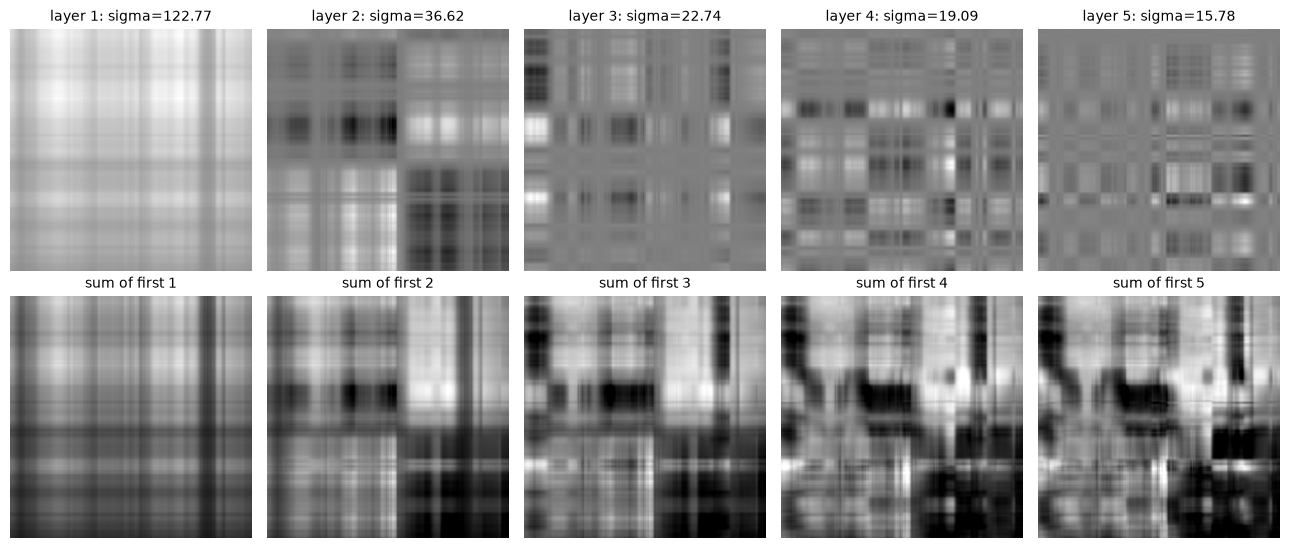

In [6]:
K = 5
fig, ax = plt.subplots(2, K, figsize=(2.6 * K, 5.6))
partial = np.zeros_like(A)
for i in range(K):
    layer = s[i] * np.outer(U[:, i], V[:, i])
    partial += layer
    lim = np.abs(layer).max()
    show(ax[0, i], layer, f"layer {i+1}: sigma={s[i]:.2f}", cmap="gray", vmin=-lim, vmax=lim)
    show(ax[1, i], np.clip(partial, 0, 1), f"sum of first {i+1}")
plt.tight_layout(); plt.show()

## 7. Low-rank approximation $A_k$
Truncating the sum after $k$ terms,
$$A_k=\sum_{i=1}^{k}\sigma_i u_iv_i^T = U_k\Sigma_kV_k^T,$$
gives a rank-$k$ matrix. Here is how the picture sharpens as $k$ grows.

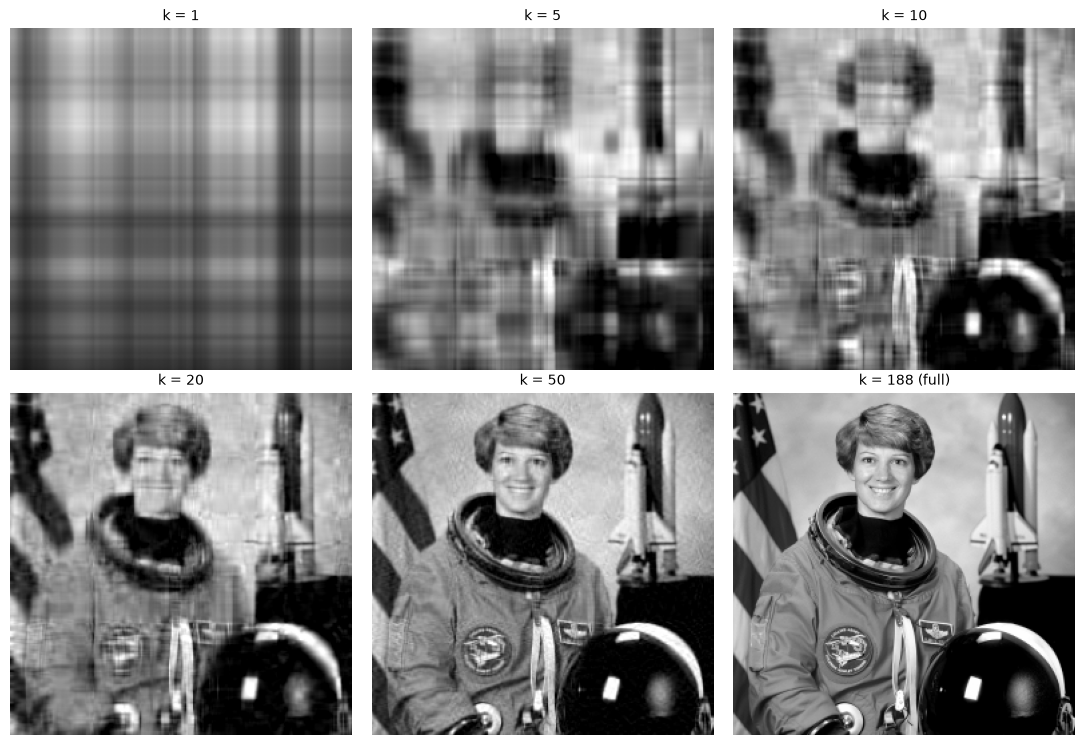

In [7]:
def approx(U, s, V, k):
    '''Rank-k approximation U_k Sigma_k V_k^T.'''
    return (U[:, :k] * s[:k]) @ V[:, :k].T

ks = [1, 5, 10, 20, 50, len(s)]
fig, ax = plt.subplots(2, 3, figsize=(11, 7.5))
for a, kk in zip(ax.flat, ks):
    show(a, np.clip(approx(U, s, V, kk), 0, 1), f"k = {kk}" + (" (full)" if kk == len(s) else ""))
plt.tight_layout(); plt.show()

## 8. Singular value decay and energy
The "size" of a matrix is measured by the Frobenius norm, $\|A\|_F^2=\sum_{ij}A_{ij}^2=\sum_i\sigma_i^2$ (because $U,V$ are orthogonal). Define the **energy captured by $k$ layers**
$$E(k)=\frac{\sum_{i\le k}\sigma_i^2}{\sum_{i}\sigma_i^2}.$$
A fast-decaying spectrum (straight-ish falling line on a log plot) means a few layers carry nearly all the energy.

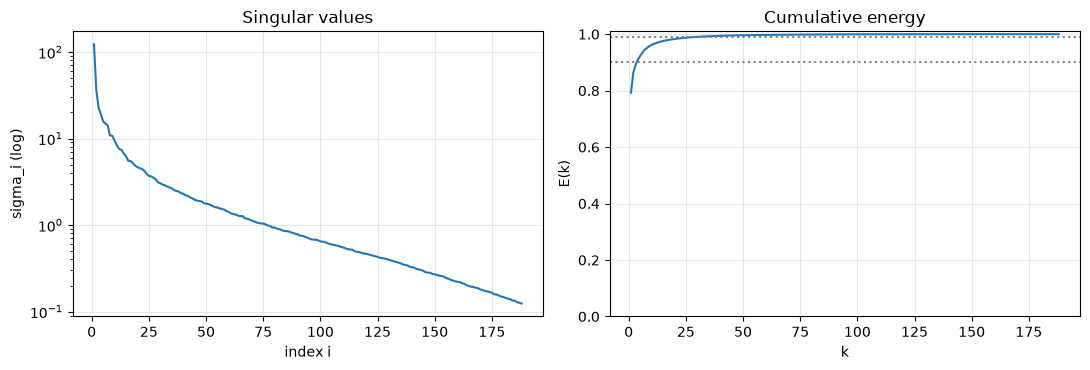

90% of the energy needs k = 4 layers
95% of the energy needs k = 8 layers
99% of the energy needs k = 30 layers


In [8]:
energy = np.cumsum(s**2) / np.sum(s**2)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].semilogy(np.arange(1, len(s) + 1), s); ax[0].set(xlabel="index i", ylabel="sigma_i (log)", title="Singular values")
ax[1].plot(np.arange(1, len(s) + 1), energy); ax[1].set(xlabel="k", ylabel="E(k)", title="Cumulative energy", ylim=(0, 1.01))
for q in (0.9, 0.99): ax[1].axhline(q, color="gray", ls=":")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()
for q in (0.90, 0.95, 0.99): print(f"{q:.0%} of the energy needs k = {int(np.searchsorted(energy, q)) + 1} layers")

## 9. Eckart–Young: truncation is optimal
**Theorem (Eckart–Young–Mirsky).** Among *all* matrices $B$ of rank at most $k$, $A_k$ is the closest to $A$:
$$\|A-A_k\|_F=\min_{\operatorname{rank}B\le k}\|A-B\|_F,\qquad \|A-A_k\|_F^2=\sum_{i>k}\sigma_i^2 .$$
(The same $A_k$ is also optimal in the spectral norm, with $\|A-A_k\|_2=\sigma_{k+1}$.) The error formula is easy to see: $A-A_k=\sum_{i>k}\sigma_iu_iv_i^T$ is itself an SVD, so its squared Frobenius norm is the sum of its squared singular values. We verify it numerically for several $k$ — the two columns should match.

   k    ||A-A_k||_F^2  sum_{i>k} s_i^2  rel. error
   1      3939.691773      3939.446480      0.4552
   5      1468.378328      1468.133036      0.2779
  10       724.982820       724.737527      0.1953
  20       326.015175       325.769882      0.1310
  50        74.788854        74.543562      0.0627
 100        11.652029        11.406737      0.0248


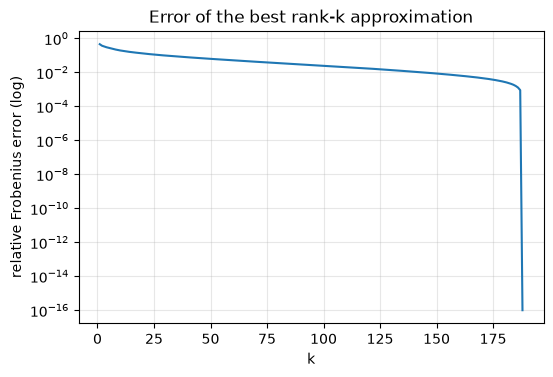

In [9]:
print(f"{'k':>4} {'||A-A_k||_F^2':>16} {'sum_{i>k} s_i^2':>16} {'rel. error':>11}")
for kk in (1, 5, 10, 20, 50, 100):
    err2 = np.sum((A - approx(U, s, V, kk))**2)          # measured directly from pixels
    tail = np.sum(s[kk:]**2)                             # predicted by the theorem
    print(f"{kk:>4} {err2:>16.6f} {tail:>16.6f} {np.sqrt(err2/np.sum(A**2)):>11.4f}")

rel = np.sqrt(np.maximum(1 - energy, 0))                  # ||A-A_k||_F / ||A||_F = sqrt(1-E(k))
plt.figure(figsize=(6, 3.8)); plt.semilogy(np.arange(1, len(s) + 1), rel + 1e-16)
plt.xlabel("k"); plt.ylabel("relative Frobenius error (log)"); plt.title("Error of the best rank-k approximation"); plt.grid(alpha=.3); plt.show()

## 10. Storage and compression ratio
Storing $A_k=U_k\Sigma_kV_k^T$ needs $U_k$ ($mk$ numbers), $V_k$ ($nk$) and $k$ singular values: $k(m+n+1)$ in total, versus $mn$ for the raw image.
$$\text{compression ratio}=\frac{mn}{k(m+n+1)},\qquad \text{we save space only if }k<\frac{mn}{m+n+1}.$$
For a square $n\times n$ image the break-even is about $k<n/2$.

raw storage m*n = 65536;  break-even k < 127.8
k=  5:   2565 numbers, ratio  25.6:1, energy 92.3%
k= 10:   5130 numbers, ratio  12.8:1, energy 96.2%
k= 20:  10260 numbers, ratio   6.4:1, energy 98.3%
k= 50:  25650 numbers, ratio   2.6:1, energy 99.6%


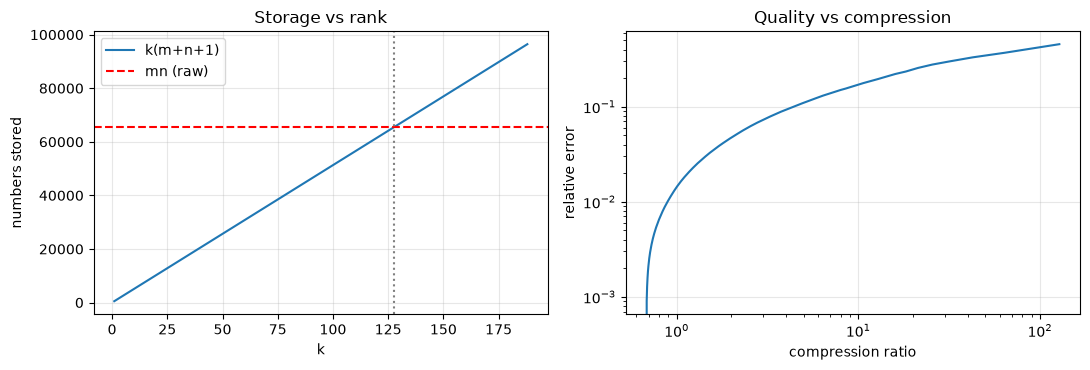

In [10]:
kk = np.arange(1, len(s) + 1)
stored = kk * (m + n + 1)
kmax = m * n / (m + n + 1)
print(f"raw storage m*n = {m*n};  break-even k < {kmax:.1f}")
for k_ in (5, 10, 20, 50): print(f"k={k_:>3}: {k_*(m+n+1):>6} numbers, ratio {m*n/(k_*(m+n+1)):5.1f}:1, energy {energy[k_-1]:.1%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(kk, stored, label="k(m+n+1)"); ax[0].axhline(m * n, color="r", ls="--", label="mn (raw)")
ax[0].axvline(kmax, color="gray", ls=":"); ax[0].set(xlabel="k", ylabel="numbers stored", title="Storage vs rank"); ax[0].legend()
ax[1].plot(m * n / stored, rel[:len(kk)]); ax[1].set(xscale="log", yscale="log", xlabel="compression ratio", ylabel="relative error", title="Quality vs compression")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 11. Colour images
A colour image is three matrices $R,G,B$ (one per channel), so we simply apply the SVD to each channel separately and recombine: $\tilde X_k=(R_k,G_k,B_k)$. Storage becomes $3k(m+n+1)$ versus $3mn$.

3 channel SVDs in 8.7 s


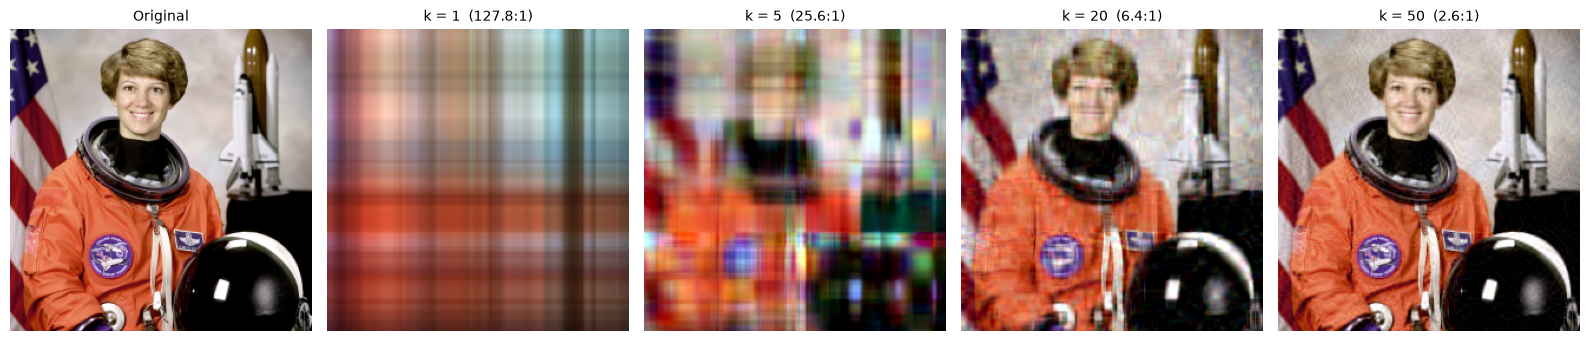

In [11]:
C = plt.imread(f"{SAMPLES}/photo-color.png").astype(float)[:, :, :3]
t0 = time.time()
svds = [my_svd(C[:, :, ch]) for ch in range(3)]           # one SVD per colour channel
print(f"3 channel SVDs in {time.time()-t0:.1f} s")

def approx_color(k):
    return np.clip(np.stack([approx(*svds[ch], k) for ch in range(3)], axis=2), 0, 1)

shown = [1, 5, 20, 50]
fig, ax = plt.subplots(1, len(shown) + 1, figsize=(3.2 * (len(shown) + 1), 3.6))
show(ax[0], C, "Original")
for a, kk in zip(ax[1:], shown):
    show(a, approx_color(kk), f"k = {kk}  ({C.shape[0]*C.shape[1]/(kk*(C.shape[0]+C.shape[1]+1)):.1f}:1)")
plt.tight_layout(); plt.show()

## 12. Interactive slider (optional)
If `ipywidgets` is installed, drag the slider to change $k$ live. Otherwise the cell falls back to a static three-panel figure.

In [12]:
def demo(k=10):
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    show(ax[0], A, "Original")
    show(ax[1], np.clip(approx(U, s, V, k), 0, 1), f"k = {k}, energy {energy[k-1]:.1%}, {m*n/(k*(m+n+1)):.1f}:1")
    plt.show()

try:
    from ipywidgets import interact, IntSlider
    interact(demo, k=IntSlider(value=10, min=1, max=len(s), step=1))
except ImportError:
    print("ipywidgets not installed - showing static examples instead.")
    for k_ in (2, 15, 60): demo(k_)

interactive(children=(IntSlider(value=10, description='k', max=188, min=1), Output()), _dom_classes=('widget-i…

## 13. Summary and exercises
**Summary**
* An image is a matrix; the SVD $A=U\Sigma V^T=\sum_i\sigma_iu_iv_i^T$ splits it into rank-one layers ordered by importance.
* The SVD comes from the spectral theorem applied to $A^TA$: $v_i$ = eigenvectors, $\sigma_i=\sqrt{\lambda_i}$, $u_i=Av_i/\sigma_i$. We computed it with Jacobi rotations.
* Truncating to $k$ layers is the **best** rank-$k$ approximation (Eckart–Young), with squared error $\sum_{i>k}\sigma_i^2$.
* Storage drops from $mn$ to $k(m+n+1)$; it pays off when $k<mn/(m+n+1)$. Natural images have fast-decaying $\sigma_i$, so large compression costs little quality.
* Colour images: treat each channel separately.

**Exercises**
1. By hand, find the SVD of $\begin{pmatrix}2&0\\0&-1\end{pmatrix}$ and of $\begin{pmatrix}1&1\\1&1\end{pmatrix}$. Why is the second matrix rank one?
2. Prove that $\|A\|_F^2=\sum\sigma_i^2$ using $\|A\|_F^2=\operatorname{tr}(A^TA)$.
3. Load another image from `svdcomp/demo_assets/samples/` (e.g. `checkerboard.png`, `texture.png`). Which needs fewer layers for 95% energy, and why?
4. For a $256\times256$ image, what is the largest $k$ that still saves storage? Confirm in Section 10.
5. Our $u_i=Av_i/\sigma_i$ becomes inaccurate for tiny $\sigma_i$. Explain using the condition number of $A^TA$ versus that of $A$.
6. (Challenge) Replace `jacobi_eig` with the unshifted QR algorithm built from Gram–Schmidt and compare run time and accuracy.